Authors
*   Dhruv Lalani
*   Kumar Jayant

### Part 1.a: Library Imports, installations, data ingestion, dataframe creation and basic dataframe viewing

In [1]:
# !pip install shap
# !pip install lime
!pip install kmodes

In [2]:

# Import necessary libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import ParameterGrid
import shap
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.manifold import TSNE
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.pipeline import Pipeline
from kmodes.kprototypes import KPrototypes
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples
from yellowbrick.cluster import SilhouetteVisualizer
from sklearn.cluster import KMeans
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
import statsmodels.formula.api as smf   # <- use alias smf

In [3]:
# Load the data
file_path = "/content/Employee_Performance_Imputed_Distribution.csv"
df = pd.read_csv(file_path, encoding='ISO-8859-1')

In [4]:
df1 = df.copy()
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 40 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   ï»¿EmpNumber                                    1200 non-null   object 
 1   Age                                             1200 non-null   int64  
 2   Gender                                          1200 non-null   object 
 3   EducationBackground                             1200 non-null   object 
 4   MaritalStatus                                   1200 non-null   object 
 5   EmpDepartment                                   1200 non-null   object 
 6   EmpJobRole                                      1200 non-null   object 
 7   BusinessTravelFrequency                         1200 non-null   object 
 8   DistanceFromHome                                1200 non-null   int64  
 9   EmpEducationLevel                        

In [5]:
df1.describe(include='all')

,ï»¿EmpNumber,Age,Gender,EducationBackground,MaritalStatus,EmpDepartment,EmpJobRole,BusinessTravelFrequency,DistanceFromHome,EmpEducationLevel,...,Avg. sales per day,Avg. sales value,Avg. customer feedback,Salary per Annum lacs,Conversion rate,% of sales from high value products,No. of interactions per customer per customer,Product knowledge score,Customers attended M vs F,Attrition
count,1200,1200.000000,1200,1200,1200,1200,1200,1200,1200.000000,1200.00000,...,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200
unique,1200,NaN,2,6,3,6,19,3,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
top,E100998,NaN,Male,Life Sciences,Married,Sales,Sales Executive,Travel_Rarely,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No
freq,1,NaN,725,492,548,373,270,846,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1022
mean,NaN,36.918333,NaN,NaN,NaN,NaN,NaN,NaN,9.165833,2.89250,...,3.073333,80787.740966,3.822703,173403.234167,0.282801,0.494979,2.509988,70.086117,0.497627,NaN
std,NaN,9.087289,NaN,NaN,NaN,NaN,NaN,NaN,8.176636,1.04412,...,1.627932,66695.892951,0.581585,61183.687363,0.158739,0.193158,0.785093,15.084054,0.153547,NaN
min,NaN,18.000000,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,1.00000,...,1.000000,6309.890714,2.007100,100000.000000,0.003978,0.021883,1.000000,17.959454,0.096448,NaN
25%,NaN,30.000000,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,2.00000,...,2.000000,39091.849998,3.405167,128109.000000,0.159366,0.356281,1.941221,60.324204,0.386389,NaN
50%,NaN,36.000000,NaN,NaN,NaN,NaN,NaN,NaN,7.000000,3.00000,...,3.000000,60499.892965,3.847021,160467.500000,0.265613,0.498386,2.492675,70.301358,0.496871,NaN
75%,NaN,43.000000,NaN,NaN,NaN,NaN,NaN,NaN,14.000000,4.00000,...,4.000000,100298.915825,4.218426,202719.750000,0.379195,0.638837,3.051227,80.259251,0.604345,NaN


In [6]:
# Check for missing values
df1.isnull().sum()

,0
ï»¿EmpNumber,0
Age,0
Gender,0
EducationBackground,0
MaritalStatus,0
EmpDepartment,0
EmpJobRole,0
BusinessTravelFrequency,0
DistanceFromHome,0
EmpEducationLevel,0


### Part 1.b: Data preprocessing

Remove perfectly correlated data

Scale data to input into unsupervised clustering

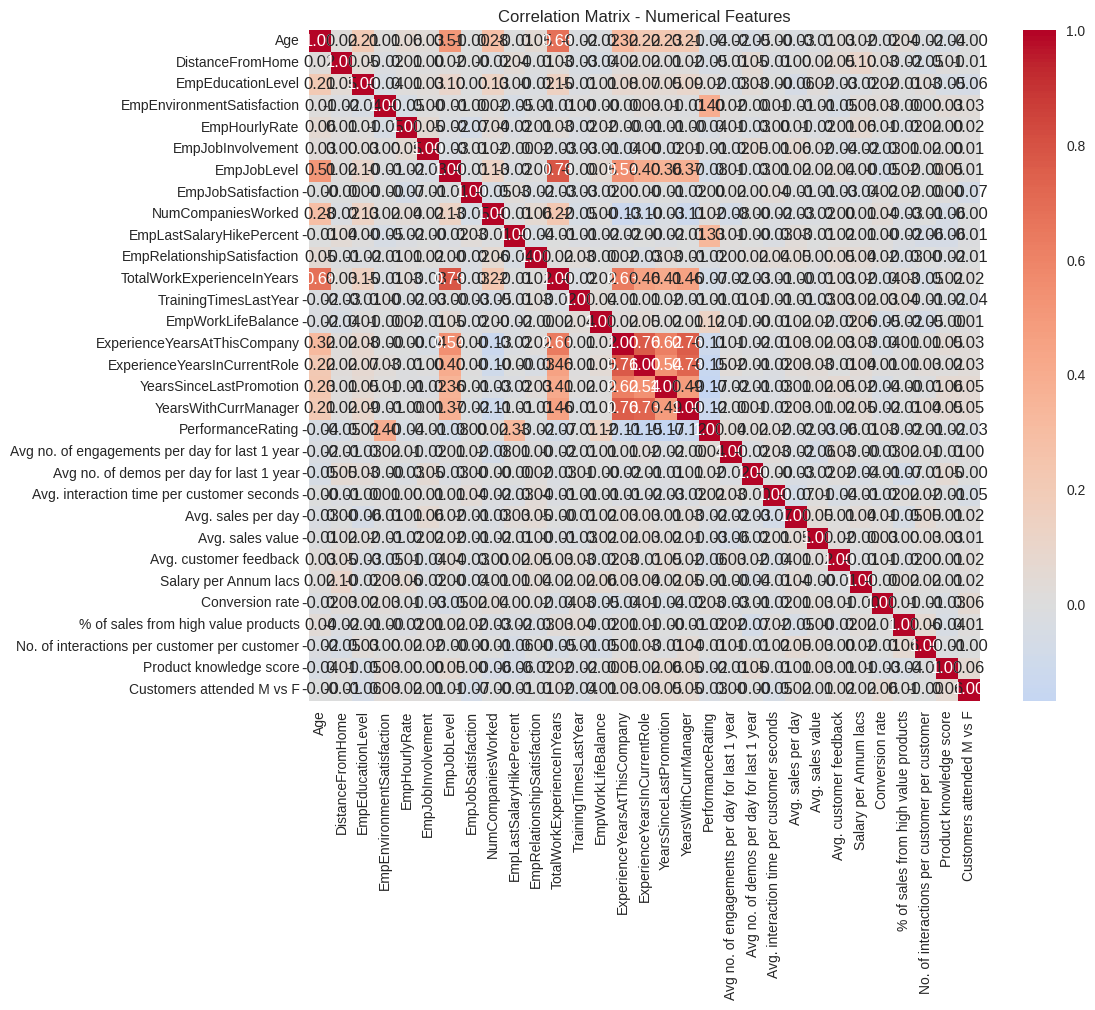

In [7]:
num_columns = df1.select_dtypes(include=['int64', 'float64'],  # only ints & floats
                             exclude=['object']             # exclude object
                            ).columns.tolist()

# Extract numerical data only
df_numeric = df1[num_columns]

# Plot correlation matrix
plt.figure(figsize=(12, 10))
correlation_matrix = df_numeric.corr()
sns.heatmap(correlation_matrix,
            annot=True,          # Show correlation values
            cmap='coolwarm',     # Color scheme
            center=0,            # Center colorbar at 0
            square=True,         # Square cells
            fmt='.2f')           # 2 decimal places
plt.title('Correlation Matrix - Numerical Features')
plt.tight_layout()
plt.show()

In [8]:
# isolate columns with high correlation say > 0.9

high_corr = correlation_matrix[abs(correlation_matrix) > 0.9].stack().reset_index()
high_corr.columns = ['var1', 'var2', 'corr']

# Filter out self-correlations (var1 != var2)
high_corr = high_corr[high_corr['var1'] != high_corr['var2']]

high_corr

,var1,var2,corr


There no columns with high/perfect correlation hence we can continue with all the columns/features.

Now scale the numeric data, create a dataframe with scaled numeric data and merge it with categorical data from the original dataframe in preparation for unsupervised k proto clustering

In [9]:
# Scale the numerical data
scaler = StandardScaler()
df_numeric_scaled = pd.DataFrame(
    scaler.fit_transform(df_numeric),
    columns=df_numeric.columns,
    index=df_numeric.index
)

# Extract categorical columns from df1 (object dtype)
cat_columns = df1.select_dtypes(include=['object']).columns.tolist()
df_categorical = df1[cat_columns].copy()

# Convert categoricals to string (for k-prototypes compatibility)
for col in cat_columns:
    df_categorical[col] = df_categorical[col].astype(str)

# Merge scaled numeric + original categorical data
df2 = pd.concat([df_numeric_scaled, df_categorical], axis=1)

print("df2 shape:", df2.shape)
print("\nData types in df2:")
print(df2.dtypes.value_counts())

df2 shape: (1200, 40)

Data types in df2:
float64    31
object      9
Name: count, dtype: int64


In [10]:
print("\nScaled numeric columns:")
print(df_numeric_scaled.columns.tolist())
print(f"number of numeric columns: {len(df_numeric_scaled.columns)}")


Scaled numeric columns:
['Age', 'DistanceFromHome', 'EmpEducationLevel', 'EmpEnvironmentSatisfaction', 'EmpHourlyRate', 'EmpJobInvolvement', 'EmpJobLevel', 'EmpJobSatisfaction', 'NumCompaniesWorked', 'EmpLastSalaryHikePercent', 'EmpRelationshipSatisfaction', 'TotalWorkExperienceInYears', 'TrainingTimesLastYear', 'EmpWorkLifeBalance', 'ExperienceYearsAtThisCompany', 'ExperienceYearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'PerformanceRating', 'Avg no. of engagements per day for last 1 year', 'Avg no. of demos per day for last 1 year', 'Avg. interaction time per customer seconds', 'Avg. sales per day', 'Avg. sales value', 'Avg. customer feedback', 'Salary per Annum lacs', 'Conversion rate', '% of sales from high value products', 'No. of interactions per customer per customer', 'Product knowledge score', 'Customers attended M vs F']
number of numeric columns: 31


In [11]:
print("\nCategorical columns:")
print(df_categorical.columns.tolist())
print(f"number of categorical columns: {len(df_categorical.columns)}")


Categorical columns:
['ï»¿EmpNumber', 'Gender', 'EducationBackground', 'MaritalStatus', 'EmpDepartment', 'EmpJobRole', 'BusinessTravelFrequency', 'OverTime', 'Attrition']
number of categorical columns: 9


### Part 2: Finding Clusters to act as pseudo labels





Creating Clusters for the synthetic dataset.

We will be using KPrototypes (instead of plain Kmeans since our data is a mix of numerical and categorical datatypes and we wish to avoid encoding).

We will be taking the following steps:

1. Using elbow method to find optimal number of clusters
2. Using KPrototypes to cluster the data

In [12]:
# Identify all columns with object datatype (typically categorical)
cat_columns = df2.select_dtypes(include=['object']).columns.tolist()

# Get their column indices for KPrototypes
cat_column_indices = [df2.columns.get_loc(col) for col in cat_columns]

for col in cat_columns:
    df2[col] = df2[col].astype(str)

X = df2.values

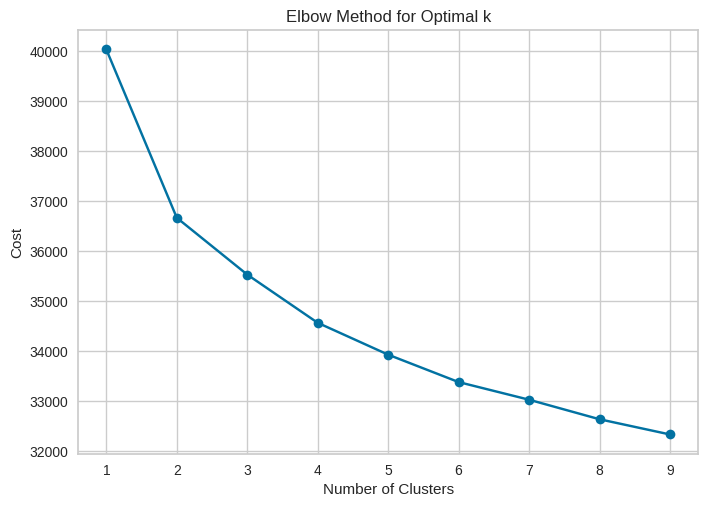

In [13]:
cost = []
for k in range(1, 10):
    kproto = KPrototypes(n_clusters=k, init='Cao')
    clusters = kproto.fit_predict(X, categorical=cat_column_indices)
    cost.append(kproto.cost_)

import matplotlib.pyplot as plt
plt.plot(range(1, 10), cost, marker = "o")
plt.xlabel('Number of Clusters')
plt.ylabel('Cost')
plt.title('Elbow Method for Optimal k')
plt.show()

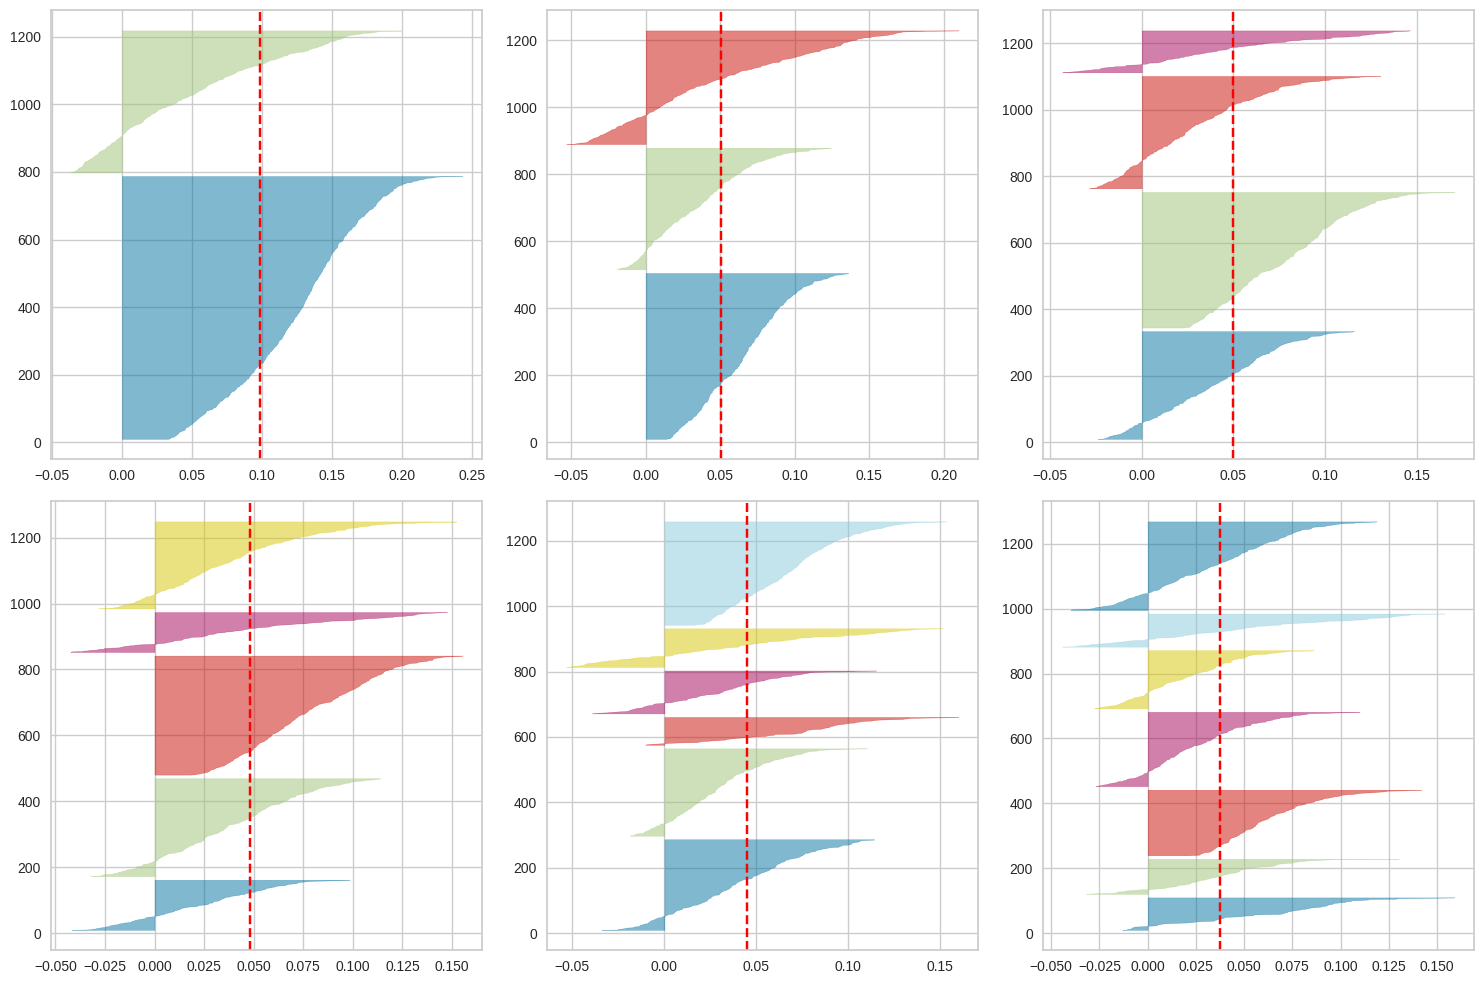

In [14]:
# vetting the number of clusters using Silhoutte visualizer
fig = plt.figure(figsize=(15, 10))
num_clusters = [2, 3, 4, 5, 6, 7]

for i, k in enumerate(num_clusters):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    ax = plt.subplot(2, 3, i+1)  # 1-based indexing
    visualizer = SilhouetteVisualizer(km, colors='yellowbrick', ax=ax)
    visualizer.fit(df_numeric_scaled)

plt.tight_layout()
plt.show()


Though we don't have clean clusters from Silhoutte plot.

3 is a reasonable number of cluster to assume for further analysis.

Next step onwards we will go ahead with 3 clusters

In [15]:
kproto = KPrototypes(n_clusters=3, init='Cao')
clusters = kproto.fit_predict(X, categorical=cat_column_indices)

# Adding cluster IDs back to the DataFrame and present the new dataset
df2['Cluster_ID'] = clusters

df2.head()

,Age,DistanceFromHome,EmpEducationLevel,EmpEnvironmentSatisfaction,EmpHourlyRate,EmpJobInvolvement,EmpJobLevel,EmpJobSatisfaction,NumCompaniesWorked,EmpLastSalaryHikePercent,...,ï»¿EmpNumber,Gender,EducationBackground,MaritalStatus,EmpDepartment,EmpJobRole,BusinessTravelFrequency,OverTime,Attrition,Cluster_ID
0,-0.541458,0.102061,0.103000,1.177978,-0.543569,0.379608,-0.060955,1.151824,-0.674538,-0.889111,...,E1001000,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,No,No,2
1,1.109888,0.591464,1.061145,1.177978,-1.187042,0.379608,-0.060955,-1.574386,-0.269410,-0.889111,...,E1001006,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,No,No,0
2,0.339260,-0.509693,1.061145,1.177978,-0.890055,-1.035081,0.842082,-1.574386,0.945974,1.594054,...,E1001007,Male,Life Sciences,Married,Sales,Sales Executive,Travel_Frequently,Yes,No,1
3,0.449349,0.102061,1.061145,-0.656641,0.347393,-1.035081,2.648157,1.151824,0.135718,-0.061389,...,E1001009,Male,Human Resources,Divorced,Human Resources,Manager,Travel_Rarely,No,No,1
4,2.541054,0.836165,1.061145,-1.573950,0.891870,0.379608,-0.060955,-1.574386,2.161359,-0.337297,...,E1001010,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,No,No,0


In [16]:
# Summarising means for all the numerical columns for the 3 clusters for observation and possible descriptive analytics

# Listing all numerical columns
num_columns = df2.select_dtypes(include=[float, int]).columns.tolist()

# Group by the cluster ID and compute mean for all numerical columns
cluster_means = df2.groupby('Cluster_ID')[num_columns].mean()

cluster_means


,Age,DistanceFromHome,EmpEducationLevel,EmpEnvironmentSatisfaction,EmpHourlyRate,EmpJobInvolvement,EmpJobLevel,EmpJobSatisfaction,NumCompaniesWorked,EmpLastSalaryHikePercent,...,Avg. interaction time per customer seconds,Avg. sales per day,Avg. sales value,Avg. customer feedback,Salary per Annum lacs,Conversion rate,% of sales from high value products,No. of interactions per customer per customer,Product knowledge score,Customers attended M vs F
Cluster_ID,,,,,,,,,,,,,,,,,,,,,
0,0.607113,0.149467,0.305002,0.009781,0.134171,0.165994,0.170593,0.048913,0.858254,0.007784,...,-0.012709,-0.104593,-0.073694,-0.011378,0.040753,0.001532,-0.002120,-0.028677,-0.086958,-0.062795
1,0.430685,-0.003765,0.166326,-0.045101,-0.032376,-0.022846,0.764234,-0.020655,-0.159979,-0.045533,...,-0.041347,0.041463,0.075224,0.064792,0.036672,-0.070766,0.028669,0.054777,0.117781,0.072092
2,-0.724501,-0.102101,-0.329216,0.024475,-0.071512,-0.100426,-0.650363,-0.019921,-0.490169,0.026174,...,0.037624,0.044477,-0.000622,-0.037034,-0.054025,0.048081,-0.018429,-0.017958,-0.020889,-0.006082


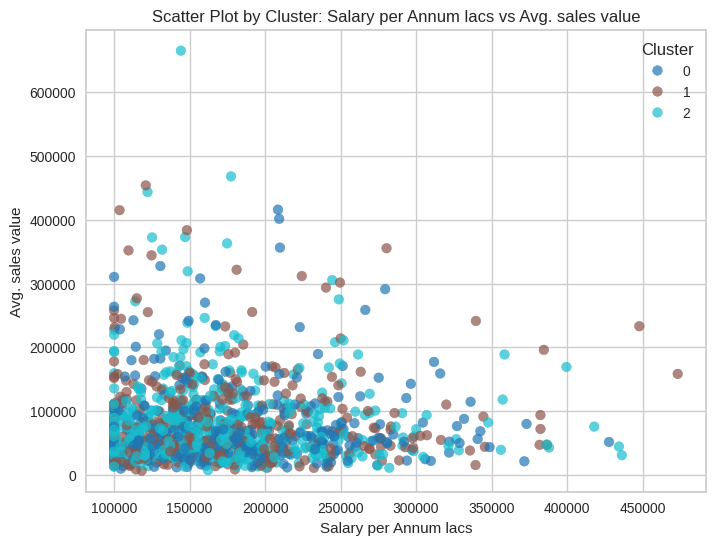

In [17]:
# Scatter plot by clusters with two columns for visual representation

# Superimposing Clusters in original dataframe to get a more realistic view of the values
df1['Cluster_ID'] = clusters
df1.to_csv('clustered_sales_force.csv', index=False)

x_col = 'Salary per Annum lacs'
y_col = 'Avg. sales value'

plt.figure(figsize=(8,6))
scatter = plt.scatter(df1[x_col], df1[y_col], c=df1['Cluster_ID'], cmap='tab10', alpha=0.7)
plt.xlabel(x_col)
plt.ylabel(y_col)
plt.title('Scatter Plot by Cluster: {} vs {}'.format(x_col, y_col))
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.show()

**Cluster Profiles**

Cluster 0 (teal): Low salary and low–mid sales; broad spread in sales but mostly below midrange.

Cluster 1 (green): Low salary and consistently low sales; compact, low-performing group.

Cluster 2 (brown): Mid salary and mid sales; dense band, representing stable, average performers.

Cluster 3 (grey): Highest salaries with mostly low–mid sales; relatively few points but very costly.

Cluster 4 (blue): Low–mid salaries with the highest and most dispersed sales values, including extreme high-sales outliers.

**Potential commercial Outcomes**

Cluster 0: Acceptable ROI but not outstanding; focus on upskilling and process support to lift sales without big pay increases.

Cluster 1: Low ROI segment; candidates for performance improvement plans, redeployment, or role redesign.

Cluster 2: Core engine of the field force; invest in targeted training and best-practice sharing to push them toward Cluster 4 performance.

Cluster 3: Negative or weak ROI; prioritize diagnostic reviews, territory/role changes, or compensation realignment to justify high cost.

Cluster 4: Highest ROI group; protect and reward, use as benchmark for hiring, coaching, and incentive design, and study their behaviors to replicate success across other clusters.

### Part 3: ANOVA with linear regression to see if the classification with pseudo labels and all the indepdent numerical variables are needed.

In [18]:
# The Linreg shall be done with numerical variables only

# Creating the dataset with pseudo labels and unscaled numerical data
df_numeric['Cluster_ID'] = clusters

/tmp/ipykernel_4185/436602501.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_numeric['Cluster_ID'] = clusters


In [19]:
df_numeric

,Age,DistanceFromHome,EmpEducationLevel,EmpEnvironmentSatisfaction,EmpHourlyRate,EmpJobInvolvement,EmpJobLevel,EmpJobSatisfaction,NumCompaniesWorked,EmpLastSalaryHikePercent,...,Avg. sales per day,Avg. sales value,Avg. customer feedback,Salary per Annum lacs,Conversion rate,% of sales from high value products,No. of interactions per customer per customer,Product knowledge score,Customers attended M vs F,Cluster_ID
0,32,10,3,4,55,3,2,4,1,12,...,3,40096.77000,3.781753,195769,0.104787,0.229816,1.961721,79.497775,0.415024,2
1,47,14,4,4,42,3,2,1,2,12,...,3,16918.86777,2.865392,212194,0.470160,0.448324,1.733028,66.959862,0.411644,0
2,40,5,4,4,48,2,3,1,5,21,...,1,232745.48780,3.722888,173590,0.290968,0.146805,1.629473,74.003103,0.415218,1
3,41,10,4,2,73,2,5,4,3,15,...,4,351944.31070,4.395204,109538,0.271255,0.286976,4.735974,65.882153,0.352787,1
4,60,16,4,1,84,3,2,1,8,14,...,4,33871.45925,3.161762,105672,0.167018,0.824831,2.649225,66.272329,0.514202,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1195,27,3,1,4,71,4,2,4,1,20,...,1,44971.90873,2.650985,104262,0.294705,0.368346,1.411857,66.390448,0.431843,2
1196,37,10,2,4,80,4,1,4,3,17,...,1,20779.17054,3.341156,171886,0.091198,0.527866,2.851629,100.000000,0.342820,2
1197,50,28,1,4,74,4,1,3,1,11,...,2,100058.58600,4.091902,268153,0.108040,0.471059,2.421334,68.209283,0.491932,1
1198,34,9,3,4,46,2,3,2,1,14,...,5,58628.08936,3.881840,149922,0.349348,0.424042,2.826687,27.571655,0.702825,1


In [20]:
# Setting up the linreg

target = 'Cluster_ID'
predictors = df_numeric.columns.drop('Cluster_ID')                 # all other columns
formula = target + " ~ " + " + ".join(predictors)
print(formula)

Cluster_ID ~ Age + DistanceFromHome + EmpEducationLevel + EmpEnvironmentSatisfaction + EmpHourlyRate + EmpJobInvolvement + EmpJobLevel + EmpJobSatisfaction + NumCompaniesWorked + EmpLastSalaryHikePercent + EmpRelationshipSatisfaction + TotalWorkExperienceInYears + TrainingTimesLastYear + EmpWorkLifeBalance + ExperienceYearsAtThisCompany + ExperienceYearsInCurrentRole + YearsSinceLastPromotion + YearsWithCurrManager + PerformanceRating + Avg no. of engagements per day for last 1 year + Avg no. of demos per day for last 1 year + Avg. interaction time per customer seconds + Avg. sales per day + Avg. sales value + Avg. customer feedback + Salary per Annum lacs + Conversion rate + % of sales from high value products + No. of interactions per customer per customer + Product knowledge score + Customers attended M vs F


In [21]:
import re

# Sanitize column names for patsy compatibility
def sanitize_col_name(col_name):
    # Replace spaces with underscores
    sanitized = re.sub(r'\s+', '_', col_name)
    # Remove or replace other special characters
    sanitized = re.sub(r'[^a-zA-Z0-9_]', '', sanitized)
    # Ensure it doesn't start with a number (patsy limitation)
    if re.match(r'^\d', sanitized):
        sanitized = '_' + sanitized
    return sanitized

# Apply sanitization to df_numeric column names
sanitized_columns = {col: sanitize_col_name(col) for col in df_numeric.columns}
df_numeric_sanitized = df_numeric.rename(columns=sanitized_columns)

# Recreate predictors and formula with sanitized names
target = 'Cluster_ID'
predictors = df_numeric_sanitized.columns.drop('Cluster_ID')
formula = target + " ~ " + " + ".join(predictors)

# Fitting the lin reg model and printing the coefficients table
model = ols(formula, data=df_numeric_sanitized).fit()


In [22]:
# Anova summary to see if the overall model has right F statistic and error to carry on

anova_table = anova_lm(model, typ=1)

print("\nANOVA table:")
anova_table


ANOVA table:


,df,sum_sq,mean_sq,F,PR(>F)
Age,1.0,276.549039,276.549039,924.180222,5.033028e-150
DistanceFromHome,1.0,6.988275,6.988275,23.353636,1.527267e-06
EmpEducationLevel,1.0,19.305171,19.305171,64.514622,2.324124e-15
EmpEnvironmentSatisfaction,1.0,0.068100,0.068100,0.227577,6.334154e-01
EmpHourlyRate,1.0,1.701013,1.701013,5.684500,1.727433e-02
EmpJobInvolvement,1.0,6.318597,6.318597,21.115684,4.793338e-06
EmpJobLevel,1.0,11.042720,11.042720,36.902906,1.677447e-09
EmpJobSatisfaction,1.0,0.951508,0.951508,3.179778,7.481448e-02
NumCompaniesWorked,1.0,129.859577,129.859577,433.968793,3.306619e-82
EmpLastSalaryHikePercent,1.0,0.034153,0.034153,0.114135,7.355452e-01


In [23]:
anova_table_2 = anova_lm(model, typ=2)

print("\nANOVA table_2:")
anova_table_2


ANOVA table_2:


,sum_sq,df,F,PR(>F)
Age,45.086776,1.0,150.672395,1.156133e-32
DistanceFromHome,7.857134,1.0,26.257214,3.494087e-07
EmpEducationLevel,12.975833,1.0,43.363045,6.857090e-11
EmpEnvironmentSatisfaction,0.098318,1.0,0.328561,5.666179e-01
EmpHourlyRate,1.181571,1.0,3.948610,4.714339e-02
EmpJobInvolvement,7.155395,1.0,23.912121,1.149157e-06
EmpJobLevel,8.119472,1.0,27.133905,2.242325e-07
EmpJobSatisfaction,2.845083,1.0,9.507786,2.094013e-03
NumCompaniesWorked,87.823915,1.0,293.492703,7.254981e-59
EmpLastSalaryHikePercent,0.126718,1.0,0.423471,5.153383e-01


In [24]:
# Regression summary with coefficients table

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             Cluster_ID   R-squared:                       0.581
Model:                            OLS   Adj. R-squared:                  0.569
Method:                 Least Squares   F-statistic:                     52.15
Date:                Sun, 29 Mar 2026   Prob (F-statistic):          7.97e-196
Time:                        07:43:39   Log-Likelihood:                -962.60
No. Observations:                1200   AIC:                             1989.
Df Residuals:                    1168   BIC:                             2152.
Df Model:                          31                                         
Covariance Type:            nonrobust                                         
                                                    coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------

In [25]:
# Extract coefficient table
table = model.summary().tables[1]
coef_table = pd.DataFrame(table.data[1:], columns=table.data[0])
coef_table = coef_table.rename(columns={coef_table.columns[0]: 'Variable'})

# P-values as numeric
coef_table['P>|t|'] = pd.to_numeric(coef_table['P>|t|'], errors='coerce')

# Variables (skip Intercept) and p-values
variables = coef_table['Variable'].iloc[1:].tolist()
p_vals    = coef_table['P>|t|'].iloc[1:].tolist()
var_pvals_dict = dict(zip(variables, p_vals))

significant_vars   = [v for v, p in var_pvals_dict.items() if p <= 0.06] # should have been 0.05, letting loose slightly
insignificant_vars = [v for v, p in var_pvals_dict.items() if p > 0.06]

print("Significant vars:", significant_vars)
print("Insignificant vars:", insignificant_vars)

# Keep only significant vars that exist in df_numeric
significant_vars_existing = [v for v in significant_vars if v in df_numeric.columns]
print("Dropped (not in df_numeric):",
      [v for v in significant_vars if v not in df_numeric.columns])

# Build reduced dataset and model
target = model.model.endog_names
df_reduced = df_numeric[significant_vars_existing + [target]]
formula_reduced = f"{target} ~ " + " + ".join(significant_vars_existing)

model_reduced = smf.ols(formula_reduced, data=df_reduced).fit()
print(model_reduced.summary())

Significant vars: ['Age', 'DistanceFromHome', 'EmpEducationLevel', 'EmpHourlyRate', 'EmpJobInvolvement', 'EmpJobLevel', 'EmpJobSatisfaction', 'NumCompaniesWorked', 'TotalWorkExperienceInYears', 'TrainingTimesLastYear', 'EmpWorkLifeBalance', 'ExperienceYearsAtThisCompany', 'PerformanceRating', 'Avg_no_of_engagements_per_day_for_last_1_year', 'Avg_sales_per_day']
Insignificant vars: ['EmpEnvironmentSatisfaction', 'EmpLastSalaryHikePercent', 'EmpRelationshipSatisfaction', 'ExperienceYearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'Avg_no_of_demos_per_day_for_last_1_year', 'Avg_interaction_time_per_customer_seconds', 'Avg_sales_value', 'Avg_customer_feedback', 'Salary_per_Annum_lacs', 'Conversion_rate', '_of_sales_from_high_value_products', 'No_of_interactions_per_customer_per_customer', 'Product_knowledge_score', 'Customers_attended_M_vs_F']
Dropped (not in df_numeric): ['Avg_no_of_engagements_per_day_for_last_1_year', 'Avg_sales_per_day']
                         

### Part 4: Building the final dataset and scaling it before extracting feature importances

In [26]:
#  1   Age                                             1200 non-null   int64
#  8   DistanceFromHome                                1200 non-null   int64
#  9   EmpEducationLevel                               1200 non-null   int64
#  12  EmpJobInvolvement                               1200 non-null   int64
#  14  NumCompaniesWorked                              1200 non-null   int64
#  21  ExperienceYearsAtThisCompany                    1200 non-null   int64
#  22  ExperienceYearsInCurrentRole                    1200 non-null   int64
#  23  YearsSinceLastPromotion                         1200 non-null   int64
#  24  YearsWithCurrManager                            1200 non-null   int64
#  26  PerformanceRating                               1200 non-null   int64

In [27]:
# Build the final dataframe df3 with scaled numeric data and categorical data
df_numeric_scaled.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 31 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Age                                             1200 non-null   float64
 1   DistanceFromHome                                1200 non-null   float64
 2   EmpEducationLevel                               1200 non-null   float64
 3   EmpEnvironmentSatisfaction                      1200 non-null   float64
 4   EmpHourlyRate                                   1200 non-null   float64
 5   EmpJobInvolvement                               1200 non-null   float64
 6   EmpJobLevel                                     1200 non-null   float64
 7   EmpJobSatisfaction                              1200 non-null   float64
 8   NumCompaniesWorked                              1200 non-null   float64
 9   EmpLastSalaryHikePercent                 

In [28]:
df_categorical.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   ï»¿EmpNumber             1200 non-null   object
 1   Gender                   1200 non-null   object
 2   EducationBackground      1200 non-null   object
 3   MaritalStatus            1200 non-null   object
 4   EmpDepartment            1200 non-null   object
 5   EmpJobRole               1200 non-null   object
 6   BusinessTravelFrequency  1200 non-null   object
 7   OverTime                 1200 non-null   object
 8   Attrition                1200 non-null   object
dtypes: object(9)
memory usage: 84.5+ KB


In [30]:
df3 = df_numeric_scaled[['Age','DistanceFromHome','EmpEducationLevel','EmpJobInvolvement',
                         'NumCompaniesWorked','ExperienceYearsAtThisCompany','ExperienceYearsInCurrentRole',
                         'YearsSinceLastPromotion','YearsWithCurrManager','PerformanceRating']]
df3 = pd.concat([df3, df_categorical], axis=1)
df3.drop(['ï»¿EmpNumber'], axis=1, inplace=True)
df3['Cluster_ID'] = clusters

df3

,Age,DistanceFromHome,EmpEducationLevel,EmpJobInvolvement,NumCompaniesWorked,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,PerformanceRating,Gender,EducationBackground,MaritalStatus,EmpDepartment,EmpJobRole,BusinessTravelFrequency,OverTime,Attrition,Cluster_ID
0,-0.541458,0.102061,0.103000,0.379608,-0.674538,0.468778,0.749766,-0.681372,1.100251,0.099618,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,No,No,2
1,1.109888,0.591464,1.061145,0.379608,-0.269410,-0.012431,0.749766,-0.370834,0.817773,0.099618,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,No,No,0
2,0.339260,-0.509693,1.061145,-1.035081,0.945974,1.752001,2.410786,-0.370834,2.230163,2.027702,Male,Life Sciences,Married,Sales,Sales Executive,Travel_Frequently,Yes,No,1
3,0.449349,0.102061,1.061145,-1.035081,0.135718,2.233210,0.472929,3.045084,0.535296,0.099618,Male,Human Resources,Divorced,Human Resources,Manager,Travel_Rarely,No,No,1
4,2.541054,0.836165,1.061145,0.379608,2.161359,-0.814446,-0.634417,-0.060296,-0.594616,0.099618,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,No,No,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1195,-1.091906,-0.754394,-1.813288,1.794297,-0.674538,-0.172834,0.196093,-0.681372,-0.029660,2.027702,Female,Medical,Divorced,Sales,Sales Executive,Travel_Frequently,Yes,No,2
1196,0.008991,0.102061,-0.855144,1.794297,0.135718,-0.974849,-1.188091,-0.681372,-1.159572,0.099618,Male,Life Sciences,Single,Development,Senior Developer,Travel_Rarely,No,No,2
1197,1.440157,2.304373,-1.813288,1.794297,-0.674538,2.072807,1.026603,0.250242,1.100251,0.099618,Male,Medical,Married,Development,Senior Developer,Travel_Rarely,Yes,No,1
1198,-0.321278,-0.020290,0.103000,-1.035081,-0.674538,0.147972,0.749766,1.492394,0.817773,0.099618,Female,Medical,Single,Data Science,Data Scientist,Travel_Rarely,No,No,1


In [31]:
# Isolating categorical features for encoding
# Since we have both nominal and ordinal features we shall be using label encoding for ordinal and OHE for nominal features.
# Nominal features: Gender, MaritalStatus, EmpDepartment, EmpJobRole, Attrition
# Ordinal features: EducationBackground, BusinessTravelFrequency, OverTime

onehot_cols = ['Gender', 'MaritalStatus', 'EmpDepartment']
label_cols = ['EducationBackground', 'BusinessTravelFrequency', 'OverTime', 'EmpJobRole','Attrition']

In [32]:
# Label encoding code block

for col in label_cols:
    le = LabelEncoder()
    df3[col + '_le'] = le.fit_transform(df3[col].astype(str))

# Each encoded column has suffix of '_le' to ensure identifiability of being label encoded

# Drop original categorical columns
df3.drop(columns=label_cols, inplace=True)

In [33]:
# OHE code block

df3 = pd.get_dummies(df3, columns=onehot_cols, drop_first=False)

# Do note that we are retaining all the encoded columns. This is beacuse we shall be using all tree base algorithms.
# Dropping one encoded column is needed for regression to avoid perfect collinearity

In [34]:
df3

,Age,DistanceFromHome,EmpEducationLevel,EmpJobInvolvement,NumCompaniesWorked,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,PerformanceRating,...,Gender_Male,MaritalStatus_Divorced,MaritalStatus_Married,MaritalStatus_Single,EmpDepartment_Data Science,EmpDepartment_Development,EmpDepartment_Finance,EmpDepartment_Human Resources,EmpDepartment_Research & Development,EmpDepartment_Sales
0,-0.541458,0.102061,0.103000,0.379608,-0.674538,0.468778,0.749766,-0.681372,1.100251,0.099618,...,True,False,False,True,False,False,False,False,False,True
1,1.109888,0.591464,1.061145,0.379608,-0.269410,-0.012431,0.749766,-0.370834,0.817773,0.099618,...,True,False,False,True,False,False,False,False,False,True
2,0.339260,-0.509693,1.061145,-1.035081,0.945974,1.752001,2.410786,-0.370834,2.230163,2.027702,...,True,False,True,False,False,False,False,False,False,True
3,0.449349,0.102061,1.061145,-1.035081,0.135718,2.233210,0.472929,3.045084,0.535296,0.099618,...,True,True,False,False,False,False,False,True,False,False
4,2.541054,0.836165,1.061145,0.379608,2.161359,-0.814446,-0.634417,-0.060296,-0.594616,0.099618,...,True,False,False,True,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1195,-1.091906,-0.754394,-1.813288,1.794297,-0.674538,-0.172834,0.196093,-0.681372,-0.029660,2.027702,...,False,True,False,False,False,False,False,False,False,True
1196,0.008991,0.102061,-0.855144,1.794297,0.135718,-0.974849,-1.188091,-0.681372,-1.159572,0.099618,...,True,False,False,True,False,True,False,False,False,False
1197,1.440157,2.304373,-1.813288,1.794297,-0.674538,2.072807,1.026603,0.250242,1.100251,0.099618,...,True,False,True,False,False,True,False,False,False,False
1198,-0.321278,-0.020290,0.103000,-1.035081,-0.674538,0.147972,0.749766,1.492394,0.817773,0.099618,...,False,False,False,True,True,False,False,False,False,False


### Part 5: Feature Importances

Now we have a dataframe with Cluster ID which shall act as 'pseudo labels' when we use supervised learning algorithms and then feature ranks to find out the most important features contributing to the outcome

In [35]:
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 27 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Age                                   1200 non-null   float64
 1   DistanceFromHome                      1200 non-null   float64
 2   EmpEducationLevel                     1200 non-null   float64
 3   EmpJobInvolvement                     1200 non-null   float64
 4   NumCompaniesWorked                    1200 non-null   float64
 5   ExperienceYearsAtThisCompany          1200 non-null   float64
 6   ExperienceYearsInCurrentRole          1200 non-null   float64
 7   YearsSinceLastPromotion               1200 non-null   float64
 8   YearsWithCurrManager                  1200 non-null   float64
 9   PerformanceRating                     1200 non-null   float64
 10  Cluster_ID                            1200 non-null   uint16 
 11  EducationBackgrou

In [36]:
# Preserving original dataframe for merging in future and dropping
df4 = df3.copy()

# Define the features (X) and the target variable (y) for supervised learning algorithms

X = df3.drop(['Cluster_ID'], axis=1)
y = df3['Cluster_ID']

# Check the original class distribution to see split among cluster IDs
print("Original Class Distribution:")
print(y.value_counts(normalize=True))
print("-" * 50)

Original Class Distribution:
Cluster_ID
2    0.4175
0    0.2925
1    0.2900
Name: proportion, dtype: float64
--------------------------------------------------


In [37]:
# Splitting the dataset into train and test holds bo great meaning for this project
# Since we are only looking for feature importances and not the accuracy of the prediction
# We shall still howeever split in 90-10 ratio with stratification
# Stratification ensures that we have equal split across classes

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)


print("Training Set Class Distribution (Before Oversampling):")
print(y_train.value_counts(normalize=True))

Training Set Class Distribution (Before Oversampling):
Cluster_ID
2    0.417593
0    0.292593
1    0.289815
Name: proportion, dtype: float64


Model 1: Random forest

In [38]:
from sklearn.ensemble import RandomForestClassifier

# Create a Random Forest classifier
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)

# Fit the classifier to the training data
rf_classifier.fit(X_train, y_train)

pred_y = rf_classifier.predict(X_test)

print('Test Accuracy')
print(accuracy_score(y_test, pred_y))
print(metrics.classification_report(y_test, pred_y))

print('Train Accuracy')
pred_y = rf_classifier.predict(X_train)
print(accuracy_score(y_train, pred_y))
print(metrics.classification_report(y_train, pred_y))

Test Accuracy
0.9166666666666666
              precision    recall  f1-score   support

           0       0.91      0.86      0.88        35
           1       0.92      1.00      0.96        35
           2       0.92      0.90      0.91        50

    accuracy                           0.92       120
   macro avg       0.92      0.92      0.92       120
weighted avg       0.92      0.92      0.92       120

Train Accuracy
1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       316
           1       1.00      1.00      1.00       313
           2       1.00      1.00      1.00       451

    accuracy                           1.00      1080
   macro avg       1.00      1.00      1.00      1080
weighted avg       1.00      1.00      1.00      1080



Explainable AI Part commences here. We are looking for strongest contributing features to the outcome.

Top Contributing features from Random Forest Classifier

/tmp/ipykernel_4185/339827358.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_rank, palette='viridis')


Text(0, 0.5, 'Feature')

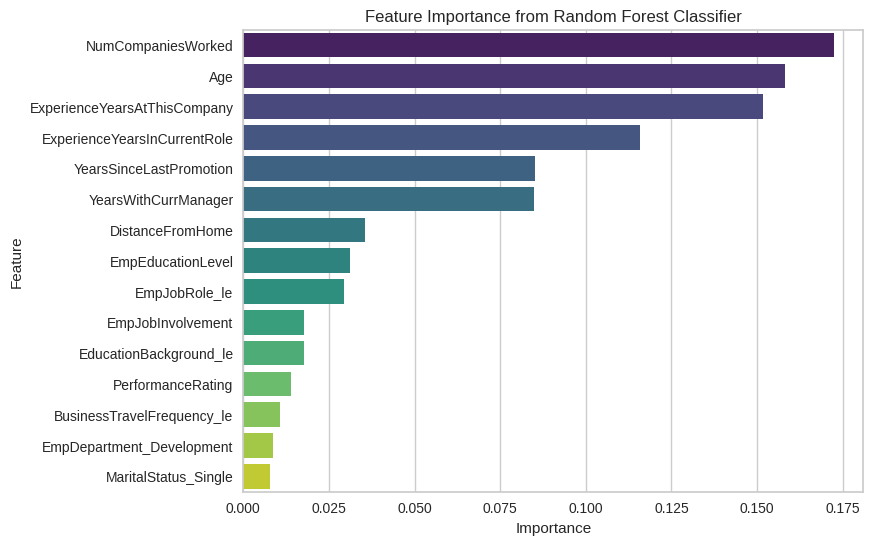

In [39]:
feature_rank = pd.DataFrame({'Feature': X_train.columns, 'Importance': rf_classifier.feature_importances_})
feature_rank = feature_rank.sort_values(by='Importance', ascending=False)

feature_rank = feature_rank[:15]

plt.figure(figsize=(8, 6))
sns.barplot(x='Importance', y='Feature', data=feature_rank, palette='viridis')
# sns.barplot(x='Importance', y='Feature', data=feature_rank)
plt.title('Feature Importance from Random Forest Classifier')
plt.xlabel('Importance')
plt.ylabel('Feature')

In [40]:
# Cumulative Rank
feature_rank['cumsum'] = feature_rank.Importance.cumsum()*100
feature_rank.head(15)

,Feature,Importance,cumsum
4,NumCompaniesWorked,0.172380,17.238017
0,Age,0.158132,33.051217
5,ExperienceYearsAtThisCompany,0.151697,48.220902
6,ExperienceYearsInCurrentRole,0.115756,59.796453
7,YearsSinceLastPromotion,0.085086,68.305013
8,YearsWithCurrManager,0.084992,76.804259
1,DistanceFromHome,0.035613,80.365527
2,EmpEducationLevel,0.031250,83.490494
13,EmpJobRole_le,0.029476,86.438099
3,EmpJobInvolvement,0.017822,88.220271


Conclusion: Top 15 features contribute 80% of the information wrt to the output variable

Model 2: Gradient Boosting

Contribution of each of the features to the outcome - using Global Shapley first.

LinearExplainer is used for Logistic Regression and Linear Regression.

explainer = shap.LinearExplainer(rf_classifier, X_train, feature_perturbation="interventional")

For Tree based models TreeExplainer is used. Tree based explainers don't use feature perturbation

In [41]:
gboost_clf = GradientBoostingClassifier(n_estimators = 500, max_depth = 10, random_state=42)

# Fit the classifier to the training data
gboost_clf.fit(X_train, y_train)

print('Train Accuracy')
pred_y = gboost_clf.predict(X_train)
print(accuracy_score(y_train, pred_y))
print(metrics.classification_report(y_train, pred_y))

print('Test Accuracy')
pred_y = gboost_clf.predict(X_test)
print(accuracy_score(y_test, pred_y))
print(metrics.classification_report(y_test, pred_y))

Train Accuracy
1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       316
           1       1.00      1.00      1.00       313
           2       1.00      1.00      1.00       451

    accuracy                           1.00      1080
   macro avg       1.00      1.00      1.00      1080
weighted avg       1.00      1.00      1.00      1080

Test Accuracy
0.9
              precision    recall  f1-score   support

           0       0.91      0.83      0.87        35
           1       0.94      0.94      0.94        35
           2       0.87      0.92      0.89        50

    accuracy                           0.90       120
   macro avg       0.91      0.90      0.90       120
weighted avg       0.90      0.90      0.90       120



Top Contributing features per the Gradient Boosting Algorithm

/tmp/ipykernel_4185/3116242855.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_rank, palette='viridis')


Text(0, 0.5, 'Feature')

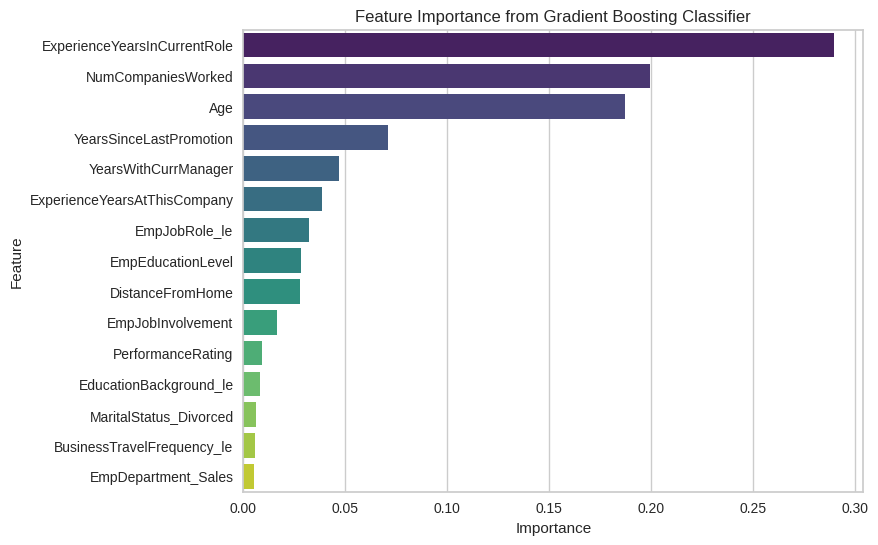

In [42]:
feature_rank = pd.DataFrame({'Feature': X_train.columns, 'Importance': gboost_clf.feature_importances_})
feature_rank = feature_rank.sort_values(by='Importance', ascending=False)

feature_rank = feature_rank[:15]

plt.figure(figsize=(8, 6))
sns.barplot(x='Importance', y='Feature', data=feature_rank, palette='viridis')
# sns.barplot(x='Importance', y='Feature', data=feature_rank)
plt.title('Feature Importance from Gradient Boosting Classifier')
plt.xlabel('Importance')
plt.ylabel('Feature')

In [43]:
# Cumulative Rank
feature_rank['cumsum'] = feature_rank.Importance.cumsum()*100
feature_rank.head(15)

,Feature,Importance,cumsum
6,ExperienceYearsInCurrentRole,0.289357,28.935719
4,NumCompaniesWorked,0.199554,48.891128
0,Age,0.187076,67.598692
7,YearsSinceLastPromotion,0.070971,74.695830
8,YearsWithCurrManager,0.046969,79.392729
5,ExperienceYearsAtThisCompany,0.038448,83.237577
13,EmpJobRole_le,0.032282,86.465814
2,EmpEducationLevel,0.028296,89.295396
1,DistanceFromHome,0.027786,92.073996
3,EmpJobInvolvement,0.016411,93.715103


Conclusion: Top 15 features contribute >99% of the information wrt to the output variable

Model 3: Extra Trees

In [44]:
from sklearn.ensemble import ExtraTreesClassifier

# Train Extra Trees Classifier
extra_clf = ExtraTreesClassifier(n_estimators=500, max_depth=10, random_state=42)
extra_clf.fit(X_train, y_train)

print('Train Accuracy')
pred_y = gboost_clf.predict(X_train)
print(accuracy_score(y_train, pred_y))
print(metrics.classification_report(y_train, pred_y))

print('Test Accuracy')
pred_y = gboost_clf.predict(X_test)
print(accuracy_score(y_test, pred_y))
print(metrics.classification_report(y_test, pred_y))

Train Accuracy
1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       316
           1       1.00      1.00      1.00       313
           2       1.00      1.00      1.00       451

    accuracy                           1.00      1080
   macro avg       1.00      1.00      1.00      1080
weighted avg       1.00      1.00      1.00      1080

Test Accuracy
0.9
              precision    recall  f1-score   support

           0       0.91      0.83      0.87        35
           1       0.94      0.94      0.94        35
           2       0.87      0.92      0.89        50

    accuracy                           0.90       120
   macro avg       0.91      0.90      0.90       120
weighted avg       0.90      0.90      0.90       120



/tmp/ipykernel_4185/1170475709.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_rank, palette='viridis')


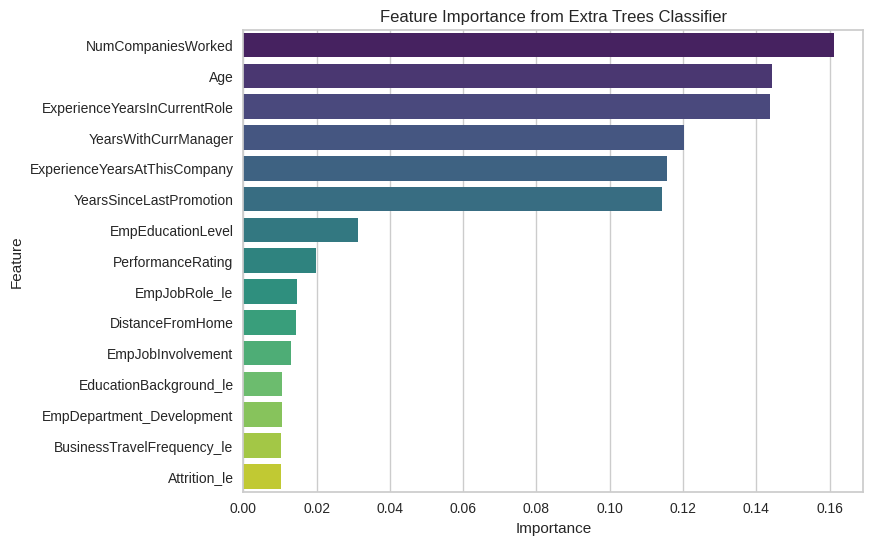

In [45]:
# Feature importances
feature_rank = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': extra_clf.feature_importances_
})
feature_rank = feature_rank.sort_values(by='Importance', ascending=False)
feature_rank = feature_rank.head(15)

# Plot top 15 most important features
plt.figure(figsize=(8, 6))
sns.barplot(x='Importance', y='Feature', data=feature_rank, palette='viridis')
plt.title('Feature Importance from Extra Trees Classifier')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

In [46]:
# Cumulative Rank
feature_rank['cumsum'] = feature_rank.Importance.cumsum()*100
feature_rank.head(25)

,Feature,Importance,cumsum
4,NumCompaniesWorked,0.161142,16.114173
0,Age,0.144278,30.541988
6,ExperienceYearsInCurrentRole,0.143697,44.911702
8,YearsWithCurrManager,0.120341,56.945836
5,ExperienceYearsAtThisCompany,0.115730,68.518868
7,YearsSinceLastPromotion,0.114192,79.938057
2,EmpEducationLevel,0.031254,83.063436
9,PerformanceRating,0.019883,85.051759
13,EmpJobRole_le,0.014789,86.530613
1,DistanceFromHome,0.014393,87.969863


Conclusion: Top 15 features contribute >99% of the information wrt to the output variable

Model 4: Logistic Regression

In [47]:
from sklearn.linear_model import LogisticRegression

# Train Logistic Regression (for multiclass, use multinomial option)
logreg_clf = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=500, random_state=42)
logreg_clf.fit(X_train, y_train)

# Evaluate model
print('Train Accuracy')
pred_y_train = logreg_clf.predict(X_train)
print(accuracy_score(y_train, pred_y_train))
print(metrics.classification_report(y_train, pred_y_train))

print('Test Accuracy')
pred_y_test = logreg_clf.predict(X_test)
print(accuracy_score(y_test, pred_y_test))
print(metrics.classification_report(y_test, pred_y_test))

Train Accuracy
0.937962962962963
              precision    recall  f1-score   support

           0       0.93      0.91      0.92       316
           1       0.96      0.96      0.96       313
           2       0.93      0.94      0.94       451

    accuracy                           0.94      1080
   macro avg       0.94      0.94      0.94      1080
weighted avg       0.94      0.94      0.94      1080

Test Accuracy
0.9166666666666666
              precision    recall  f1-score   support

           0       1.00      0.80      0.89        35
           1       0.90      1.00      0.95        35
           2       0.89      0.94      0.91        50

    accuracy                           0.92       120
   macro avg       0.93      0.91      0.92       120
weighted avg       0.92      0.92      0.92       120



/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


/tmp/ipykernel_4185/2193289545.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_rank, palette='viridis')


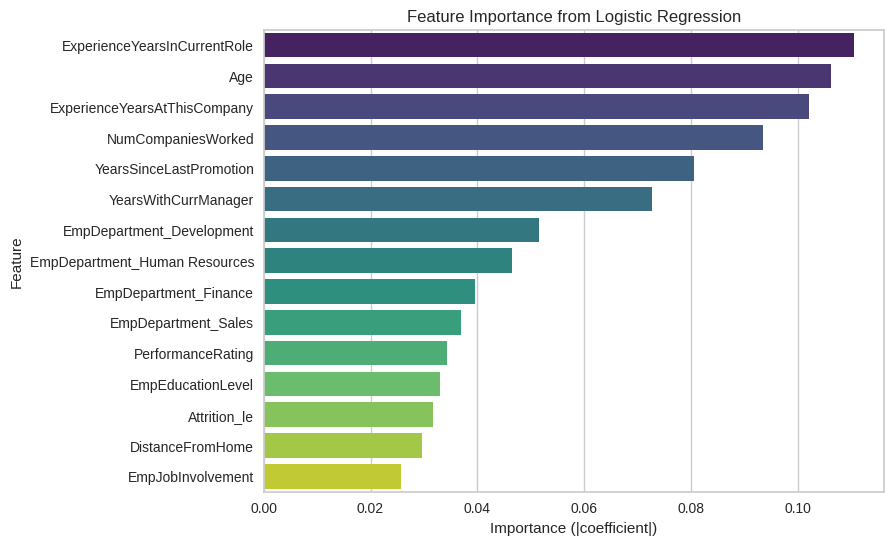

In [48]:
# Feature importances: take mean absolute across classes if multiclass
coef = logreg_clf.coef_
if coef.ndim > 1:  # multiclass case
    importances = np.mean(np.abs(coef), axis=0)
else:
    importances = np.abs(coef).flatten()

importance_sum = importances.sum()
importances_norm = importances / importance_sum


feature_rank = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importances_norm
})

feature_rank = feature_rank.sort_values(by='Importance', ascending=False)
feature_rank = feature_rank.head(15)

# Plot top 15 most important features
plt.figure(figsize=(8, 6))
sns.barplot(x='Importance', y='Feature', data=feature_rank, palette='viridis')
plt.title('Feature Importance from Logistic Regression')
plt.xlabel('Importance (|coefficient|)')
plt.ylabel('Feature')
plt.show()

In [49]:
# Cumulative Rank
feature_rank['cumsum'] = feature_rank.Importance.cumsum()*100
feature_rank.head(25)

,Feature,Importance,cumsum
6,ExperienceYearsInCurrentRole,0.110602,11.060205
0,Age,0.106215,21.681670
5,ExperienceYearsAtThisCompany,0.102209,31.902600
4,NumCompaniesWorked,0.093481,41.250705
7,YearsSinceLastPromotion,0.080540,49.304693
8,YearsWithCurrManager,0.072695,56.574179
21,EmpDepartment_Development,0.051571,61.731247
23,EmpDepartment_Human Resources,0.046491,66.380365
22,EmpDepartment_Finance,0.039613,70.341662
25,EmpDepartment_Sales,0.036897,74.031367


Conclusion: Top 15 features contribute are being listed above. Since these are coefficients hence cumulative sum doesn't hold relevance

Model 5: Decision Tree

In [50]:
from sklearn.tree import DecisionTreeClassifier

# Train Decision Tree Classifier
tree_clf = DecisionTreeClassifier(max_depth=10, random_state=42)
tree_clf.fit(X_train, y_train)

# Evaluate model
print('Train Accuracy')
pred_y_train = tree_clf.predict(X_train)
print(accuracy_score(y_train, pred_y_train))
print(metrics.classification_report(y_train, pred_y_train))

print('Test Accuracy')
pred_y_test = tree_clf.predict(X_test)
print(accuracy_score(y_test, pred_y_test))
print(metrics.classification_report(y_test, pred_y_test))

Train Accuracy
0.9861111111111112
              precision    recall  f1-score   support

           0       0.97      0.98      0.98       316
           1       1.00      0.99      1.00       313
           2       0.99      0.98      0.99       451

    accuracy                           0.99      1080
   macro avg       0.99      0.99      0.99      1080
weighted avg       0.99      0.99      0.99      1080

Test Accuracy
0.8666666666666667
              precision    recall  f1-score   support

           0       0.82      0.80      0.81        35
           1       0.92      0.94      0.93        35
           2       0.86      0.86      0.86        50

    accuracy                           0.87       120
   macro avg       0.87      0.87      0.87       120
weighted avg       0.87      0.87      0.87       120



/tmp/ipykernel_4185/1801444763.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_rank, palette='viridis')


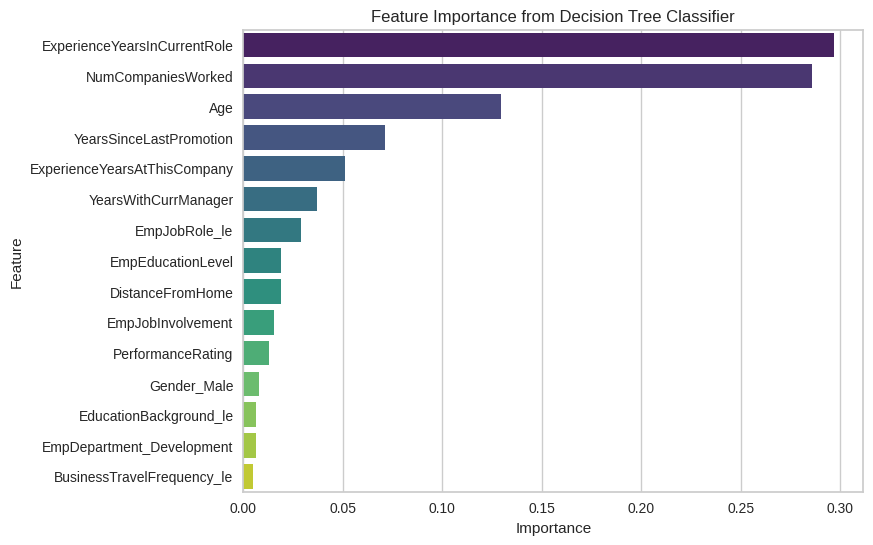

In [51]:
# Feature importances
feature_rank = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': tree_clf.feature_importances_
})
feature_rank = feature_rank.sort_values(by='Importance', ascending=False)
feature_rank = feature_rank.head(15)

# Plot top 15 most important features
plt.figure(figsize=(8, 6))
sns.barplot(x='Importance', y='Feature', data=feature_rank, palette='viridis')
plt.title('Feature Importance from Decision Tree Classifier')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

In [52]:
# Cumulative Rank
feature_rank['cumsum'] = feature_rank.Importance.cumsum()*100
feature_rank.head(25)

,Feature,Importance,cumsum
6,ExperienceYearsInCurrentRole,0.296642,29.664177
4,NumCompaniesWorked,0.285796,58.243749
0,Age,0.129484,71.192191
7,YearsSinceLastPromotion,0.071017,78.293928
5,ExperienceYearsAtThisCompany,0.050971,83.391014
8,YearsWithCurrManager,0.036859,87.076904
13,EmpJobRole_le,0.029136,89.990458
2,EmpEducationLevel,0.019024,91.892830
1,DistanceFromHome,0.018736,93.766414
3,EmpJobInvolvement,0.015465,95.312952


Conclusion: Top 9 features contribute nearly explain 100% variation in the outcome

Model 6: Final Model Stacking

**Stacking:** Using Stacking to out best performing models together

In [53]:
# Define base learners

# define base classifier with logistic regressin to be used with Adaboost
logreg_clf = LogisticRegression(random_state=42)

estimators = [
    ('lr', LogisticRegression(random_state=42, max_iter=5000)),
    ('knn', KNeighborsClassifier(n_neighbors=18)),
    ('rfc', RandomForestClassifier(n_estimators=100, random_state=42)),
    ('gboost', GradientBoostingClassifier(n_estimators = 500, max_depth = 10, random_state=42)),
    # AdaBoost with Logistic Regression as the base estimator
    ('ada_clf', AdaBoostClassifier(logreg_clf, n_estimators=100, random_state=42))
]

# Define meta learner
meta_learner = LogisticRegression(random_state=42, max_iter=5000)

# Create stacking classifier
stacking_clf = StackingClassifier(estimators=estimators, final_estimator=meta_learner)

In [54]:
# Fit the classifier to the training data
stacking_clf.fit(X_train, y_train)

StackingClassifier(estimators=[('lr',
                                LogisticRegression(max_iter=5000,
                                                   random_state=42)),
                               ('knn', KNeighborsClassifier(n_neighbors=18)),
                               ('rfc', RandomForestClassifier(random_state=42)),
                               ('gboost',
                                GradientBoostingClassifier(max_depth=10,
                                                           n_estimators=500,
                                                           random_state=42)),
                               ('ada_clf',
                                AdaBoostClassifier(estimator=LogisticRegression(random_state=42),
                                                   n_estimators=100,
                                                   random_state=42))],
                   final_estimator=LogisticRegression(max_iter=5000,
                                                      random_state=42))

In [55]:
print('Train Accuracy')
pred_y = stacking_clf.predict(X_train)
print(accuracy_score(y_train, pred_y))
print(metrics.classification_report(y_train, pred_y))

print('Test Accuracy')
pred_y = stacking_clf.predict(X_test)
print(accuracy_score(y_test, pred_y))
print(metrics.classification_report(y_test, pred_y))

Train Accuracy
0.9740740740740741
              precision    recall  f1-score   support

           0       0.96      0.96      0.96       316
           1       0.98      0.98      0.98       313
           2       0.97      0.98      0.98       451

    accuracy                           0.97      1080
   macro avg       0.97      0.97      0.97      1080
weighted avg       0.97      0.97      0.97      1080

Test Accuracy
0.925
              precision    recall  f1-score   support

           0       0.94      0.86      0.90        35
           1       0.92      1.00      0.96        35
           2       0.92      0.92      0.92        50

    accuracy                           0.93       120
   macro avg       0.93      0.93      0.92       120
weighted avg       0.93      0.93      0.92       120



Creating Feature Importance for Stacking model. Since it doesn't have a feature explainer built in we will take the help of SHAP

In [56]:
background_indices = np.random.choice(X_train.shape[0], size=100, replace=False)
X_train_subset = X_train.iloc[background_indices]  # Use .iloc for row selection by index
explainer_stacking = shap.KernelExplainer(stacking_clf.predict_proba, X_train_subset)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(


In [57]:
test_indices = np.random.choice(X_test.shape[0], size=100, replace=False)
X_test_subset = X_test.iloc[test_indices]  # Use .iloc for row selection
shap_values = explainer_stacking.shap_values(X_test_subset)

  0%|          | 0/100 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/p

In [58]:
print("Shape of X_test_subset:", X_test_subset.shape)
print("Shape of shap_values:", np.array(shap_values).shape)

Shape of X_test_subset: (100, 26)
Shape of shap_values: (100, 26, 3)


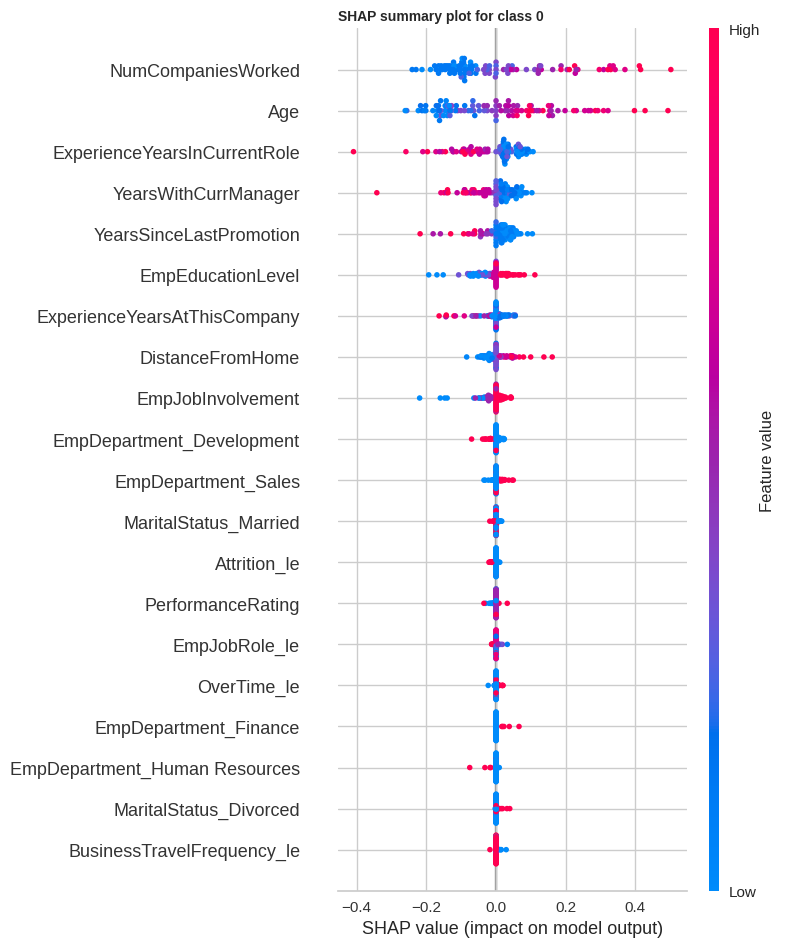

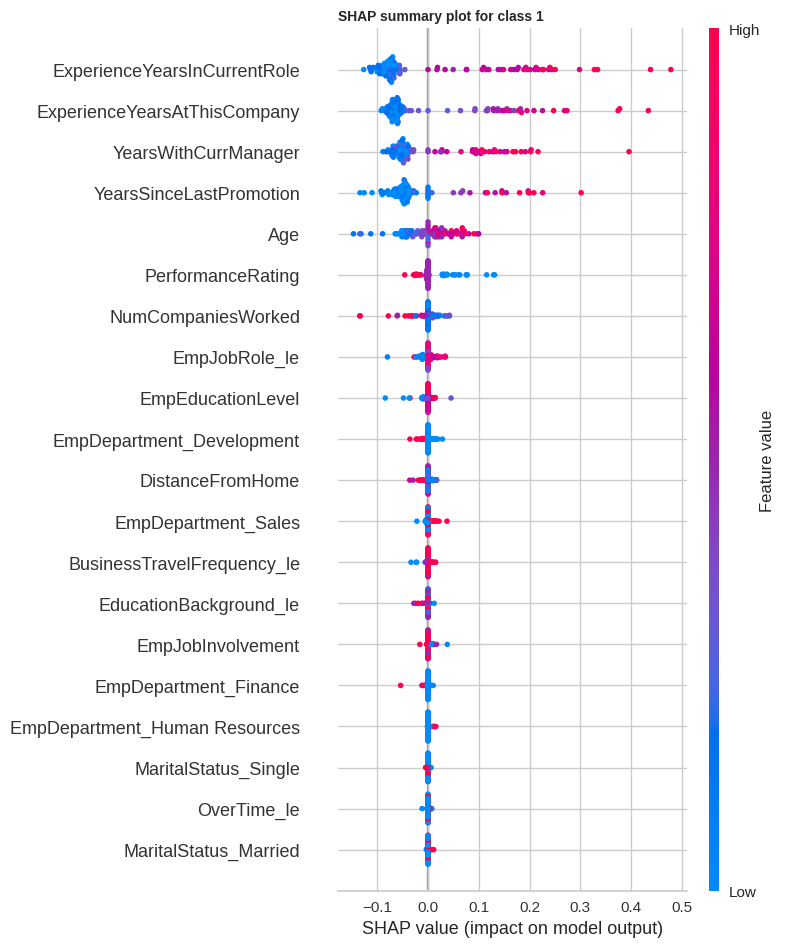

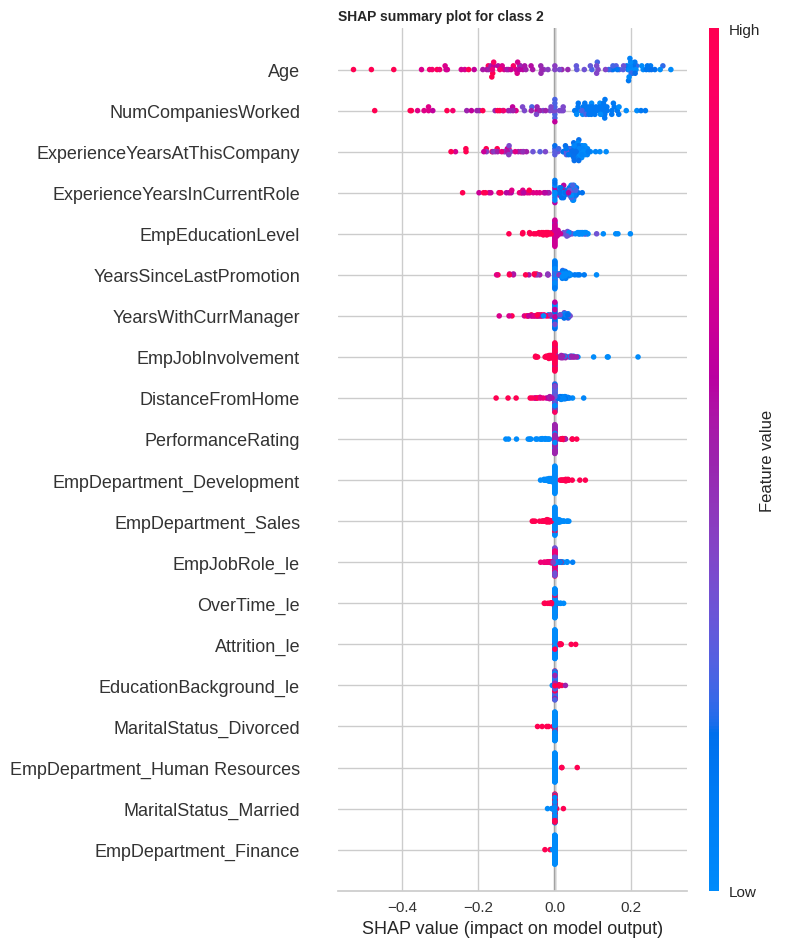

In [59]:
for class_idx in range(3):
    shap.summary_plot(
        shap_values[:, :, class_idx],
        X_test_subset,
        feature_names=X_test_subset.columns.tolist(),
        plot_type='dot',
        show=False   # Prevents immediate display so you can customize
    )
    print("\n")
    plt.title(
        f"SHAP summary plot for class {class_idx}",
        fontsize=10,
        fontweight='bold',
        loc='left'
    )
    plt.show()


End of Code